In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
import seaborn as sns

In [2]:
minimal_data = pd.read_csv("../data/minimal_features.csv")
minimal_data['Date'] = pd.to_datetime(minimal_data['Date'])
split_date = '2012-04-10' #for achieving 80/20 split
total_sales = minimal_data.groupby('Date')['Weekly_Sales'].sum().reset_index()
train_agg = total_sales[total_sales['Date'] <= split_date]
test_agg = total_sales[total_sales['Date'] > split_date]

In [3]:
def evaluate_forecast(y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # Exclude zero actuals (MAPE undefined) and NaN predictions
    valid_mask = (y_true != 0) & (~np.isnan(y_pred))
    if valid_mask.sum() == 0:
        mape = np.nan
    else:
        mape = np.mean(np.abs(
            (y_true[valid_mask] - y_pred[valid_mask]) / y_true[valid_mask]
        )) * 100

    return mae, rmse, mape

In [4]:
print(total_sales.head())

        Date  Weekly_Sales
0 2010-02-05   49750740.50
1 2010-02-12   48336677.63
2 2010-02-19   48276993.78
3 2010-02-26   43968571.13
4 2010-03-05   46871470.30


# **Naive Forecast**
Definition:
The Naive forecast predicts the next value as exactly the last observed value.

* Formula: y^(t+1) = y(t)

* Essentially, it assumes “tomorrow is like today”.

Pros:

* Extremely simple, requires no parameters.

* Often surprisingly effective for short-term forecasts when trends or seasonality are weak.

Cons:

* Misses seasonal patterns and trends.

* Does not anticipate spikes, e.g., holidays.

In [5]:
# Concatenate train + test for proper one-step alignment
full_series = pd.concat([train_agg['Weekly_Sales'], test_agg['Weekly_Sales']])

# Shift by 1 to get previous actual
naive_1step_forecast_full = full_series.shift(1)

# Extract forecasts for the test period
naive_1step_forecast = naive_1step_forecast_full.iloc[len(train_agg):].values

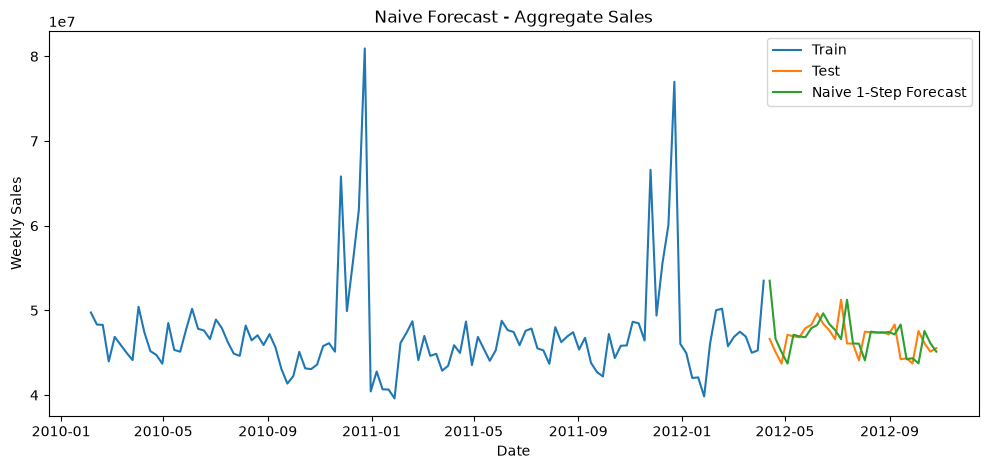

In [6]:
plt.figure(figsize=(12,5))
plt.plot(train_agg['Date'], train_agg['Weekly_Sales'], label='Train')
plt.plot(test_agg['Date'], test_agg['Weekly_Sales'], label='Test')
plt.plot(test_agg['Date'], naive_1step_forecast, label='Naive 1-Step Forecast')
plt.title("Naive Forecast - Aggregate Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.show()

In [7]:
y_true = test_agg['Weekly_Sales'].values
mae, rmse, mape = evaluate_forecast(y_true, naive_1step_forecast)
print(f"One-Step-Ahead Naive Forecast - MAE: {mae:.2f}, RMSE: {rmse:.2f}, MAPE: {mape:.2f}%")

One-Step-Ahead Naive Forecast - MAE: 1648526.29, RMSE: 2419672.68, MAPE: 3.52%


# **Moving Average Forecast**

Definition:

Predict the next value as the average of the last n observed values.

n is a parameter we choose (e.g., 4, 8, 12 weeks).

Pros:

* Smooths out short-term fluctuations

* Captures recent trend better than Naive

Cons:

* Doesn’t fully capture seasonality if n is smaller than the seasonal cycle (52 weeks for yearly data)

* Misses irregular spikes (holidays, promotions)

In [8]:
n = 4  # 4-week moving average

# Compute rolling mean of last n values, shift by 1 to make it one-step ahead
ma_1step_full = full_series.rolling(window=n).mean().shift(1)

# Extract forecasts for test period
ma_1step_forecast = ma_1step_full.iloc[len(train_agg):].values

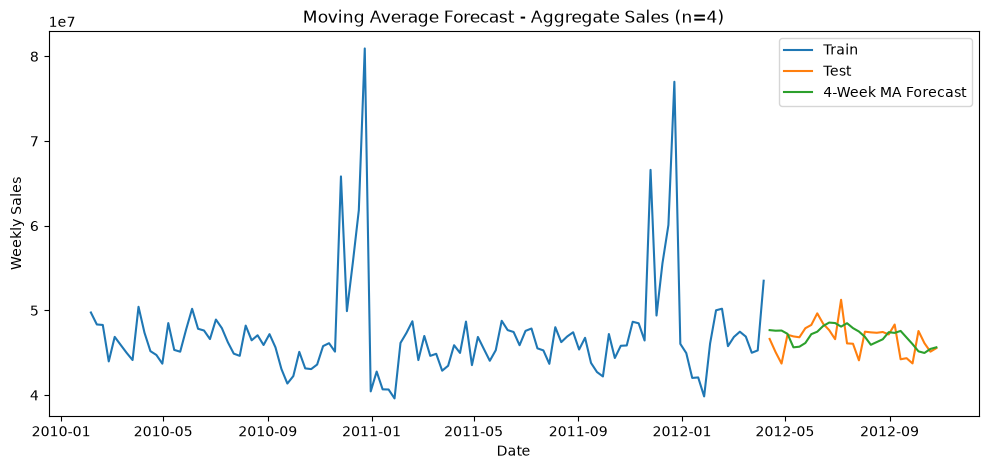

In [9]:
plt.figure(figsize=(12,5))
plt.plot(train_agg['Date'], train_agg['Weekly_Sales'], label='Train')
plt.plot(test_agg['Date'], test_agg['Weekly_Sales'], label='Test')
plt.plot(test_agg['Date'], ma_1step_forecast, label=f'{n}-Week MA Forecast')
plt.title(f"Moving Average Forecast - Aggregate Sales (n={n})")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.show()

In [10]:
y_true = test_agg['Weekly_Sales'].values
mae, rmse, mape = evaluate_forecast(y_true, ma_1step_forecast)
print(f"{n}-Week One-Step-Ahead Moving Average - MAE: {mae:.2f}, RMSE: {rmse:.2f}, MAPE: {mape:.2f}%")

4-Week One-Step-Ahead Moving Average - MAE: 1591869.67, RMSE: 1901638.14, MAPE: 3.44%


# **Seasonal Naive Forecasting**

**Definition:**

Predict the next value as the same period from the previous season.

For weekly retail data with yearly seasonality:(52 weeks lag)

Works well if there’s strong annual seasonality in your data.

**Pros:**

* Captures yearly patterns and spikes very well

* Simple to implement

**Cons:**

* Misses overall trend (increasing/decreasing sales over time)

* Cannot handle irregular events not seen in the previous year

In [11]:
seasonal_lag = 52  # weeks (~1 year)

# seasonal naive: using value from same week last year
seasonal_naive_full = full_series.shift(seasonal_lag)

# Extract forecasts for test period
seasonal_naive_forecast = seasonal_naive_full.iloc[len(train_agg):].values

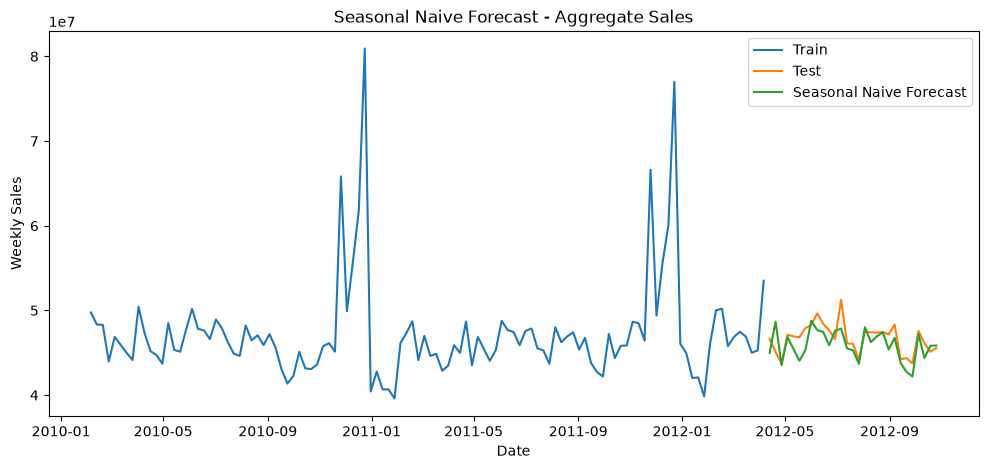

In [12]:
plt.figure(figsize=(12,5))
plt.plot(train_agg['Date'], train_agg['Weekly_Sales'], label='Train')
plt.plot(test_agg['Date'], test_agg['Weekly_Sales'], label='Test')
plt.plot(test_agg['Date'], seasonal_naive_forecast, label='Seasonal Naive Forecast')
plt.title("Seasonal Naive Forecast - Aggregate Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.show()

In [13]:
y_true = test_agg['Weekly_Sales'].values
mae, rmse, mape = evaluate_forecast(y_true, seasonal_naive_forecast)
print(f"Seasonal Naive Forecast - MAE: {mae:.2f}, RMSE: {rmse:.2f}, MAPE: {mape:.2f}%")

Seasonal Naive Forecast - MAE: 1247205.21, RMSE: 1562916.01, MAPE: 2.65%


# **Metrics Interpretation**

**One-Step-Ahead Naive Forecast:**

MAE = 1,648,526.29

RMSE = 2,419,672.68

MAPE = 3.52%

**4-Week One-Step-Ahead Moving Average:**

MAE = 1,591,869.67 (slightly lower than Naive)

RMSE = 1,901,638.14 (much lower than Naive)

MAPE = 3.44% (slightly lower than Naive)

**Seasonal Naive Forecast (52-week lag):**

MAE = 1,247,205.21 (significantly lower)

RMSE = 1,562,916.01 (significantly lower)

MAPE = 2.65% (lowest among all baselines)

# Interpretation:

**Naive Forecast:** Simple and easy to implement; tracks short-term week-to-week changes but misses seasonal peaks.

**Moving Average:** Smooths short-term fluctuations and reduces extreme errors, which lowers RMSE, but it lags behind spikes and trends.

**Seasonal Naive:** Best overall for this dataset; captures yearly seasonality and holiday peaks, significantly improving all metrics. It sets a strong benchmark for any future models like SARIMA, Prophet, or ML-based forecasts.

**Key Insight:**

While Naive and Moving Average are useful for short-term trend analysis and smoothing, Seasonal Naive is the most effective baseline for retail sales with strong yearly patterns.

Any advanced forecasting model should aim to beat the Seasonal Naive metrics, especially in MAE and RMSE.

# Store and Department Level Forecasting

In [14]:
# BASELINE FORECASTING: Store Level

#Prepare store-level weekly aggregates
store_sales = (minimal_data
               .groupby(['Store', 'Date'])['Weekly_Sales']
               .sum()
               .reset_index()
               .sort_values(['Store', 'Date']))

# Run all baselines across all stores
N_MA      = 4   # moving average window
SEAS_LAG  = 52  # seasonal lag (weeks)

results = []

for store, group in store_sales.groupby('Store'):
    group = group.sort_values('Date')

    train = group[group['Date'] <= split_date]
    test  = group[group['Date'] >  split_date]

    # Skip stores with insufficient history
    if len(train) < SEAS_LAG or len(test) == 0:
        continue

    full = pd.concat([train['Weekly_Sales'], test['Weekly_Sales']])
    y_true = test['Weekly_Sales'].values

    forecasts = {
        'Naive':          full.shift(1),
        'MA_4W':          full.rolling(N_MA).mean().shift(1),
        'Seasonal_Naive': full.shift(SEAS_LAG),
    }

    row = {'Store': store}
    for model_name, fc_series in forecasts.items():
        fc = fc_series.iloc[len(train):].values
        valid = ~np.isnan(fc)                          # handle edge NaNs
        mae, rmse, mape = evaluate_forecast(y_true[valid], fc[valid])
        row[f'{model_name}_MAE']  = round(mae, 2)
        row[f'{model_name}_RMSE'] = round(rmse, 2)
        row[f'{model_name}_MAPE'] = round(mape, 2)

    results.append(row)

store_results_df = pd.DataFrame(results)


#Summary statistics
mape_cols = ['Naive_MAPE', 'MA_4W_MAPE', 'Seasonal_Naive_MAPE']

print("=== Average MAPE across all stores ===")
print(store_results_df[mape_cols].mean().round(2).to_string())

=== Average MAPE across all stores ===
Naive_MAPE             5.26
MA_4W_MAPE             4.82
Seasonal_Naive_MAPE    5.69


In [15]:
#Which model wins per store?
store_results_df['Best_Model'] = store_results_df[mape_cols].idxmin(axis=1)

print("\n=== Best model frequency (by MAPE) ===")
print(store_results_df['Best_Model'].value_counts().to_string())



=== Best model frequency (by MAPE) ===
Best_Model
Seasonal_Naive_MAPE    21
MA_4W_MAPE             17
Naive_MAPE              7


In [16]:
#Full results table
display(store_results_df.sort_values('Seasonal_Naive_MAPE'))

,Store,Naive_MAE,Naive_RMSE,Naive_MAPE,MA_4W_MAE,MA_4W_RMSE,MA_4W_MAPE,Seasonal_Naive_MAE,Seasonal_Naive_RMSE,Seasonal_Naive_MAPE,Best_Model
30,31,45432.86,56136.79,3.31,32514.55,42214.81,2.38,29961.83,36275.43,2.15,Seasonal_Naive_MAPE
42,43,28091.59,33578.96,4.53,22277.85,26548.73,3.63,17029.52,22081.11,2.76,Seasonal_Naive_MAPE
36,37,14394.84,18034.02,2.77,10066.15,13914.41,1.94,14619.57,18155.97,2.79,MA_4W_MAPE
31,32,37738.40,46573.07,3.18,38722.61,46337.41,3.26,35581.22,44475.52,2.98,Seasonal_Naive_MAPE
11,12,44405.84,52402.12,4.50,44815.94,53952.00,4.62,33601.20,42347.93,3.33,Seasonal_Naive_MAPE
39,40,77562.40,102429.51,7.90,61041.60,69813.52,6.18,33184.11,40913.38,3.34,Seasonal_Naive_MAPE
25,26,60882.92,78067.75,5.94,46545.46,59045.03,4.52,36095.68,43889.24,3.50,Seasonal_Naive_MAPE
21,22,55463.97,74676.97,5.56,47443.39,60443.47,4.76,35761.38,53091.32,3.50,Seasonal_Naive_MAPE
9,10,66311.56,80440.80,3.69,65255.80,85652.48,3.70,65983.19,86403.80,3.67,Seasonal_Naive_MAPE
18,19,77046.37,101429.80,5.53,78555.67,95508.68,5.67,51435.11,70430.38,3.75,Seasonal_Naive_MAPE


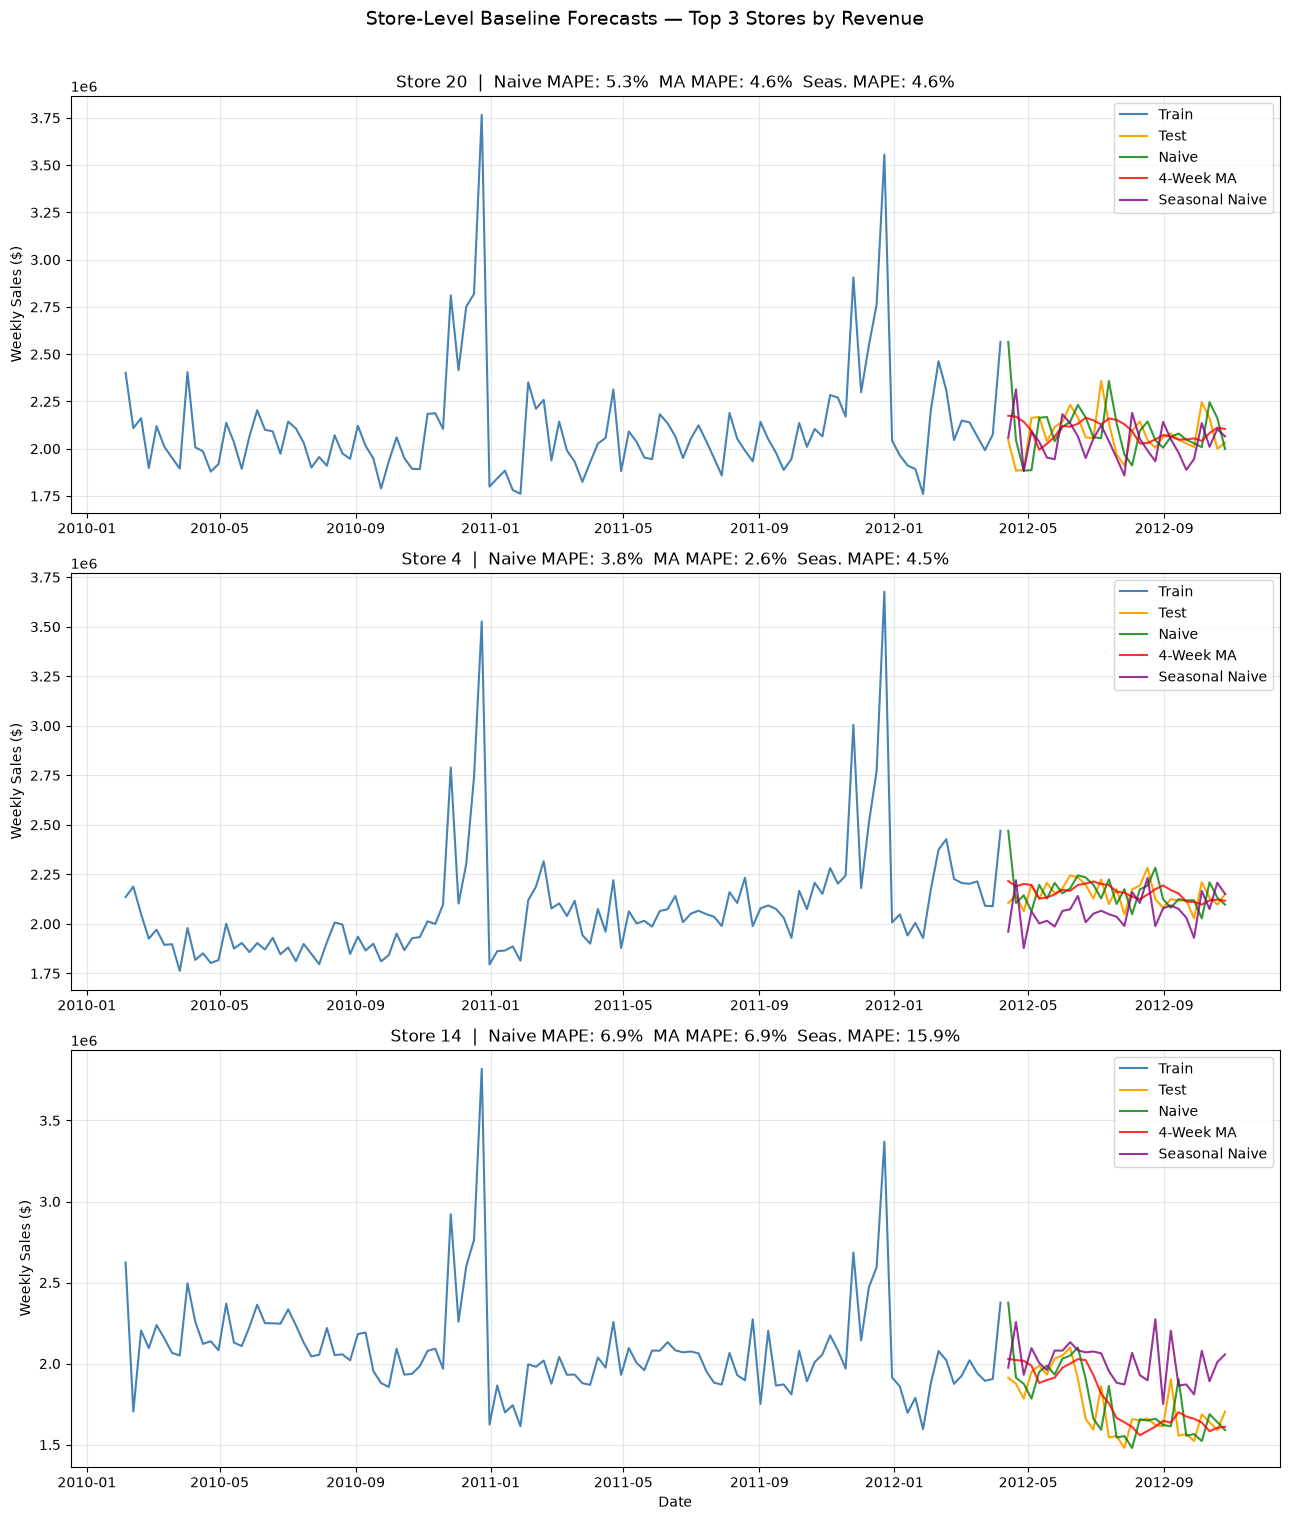

In [17]:
# Plot top 3 stores by total sales
top_stores = (store_sales
              .groupby('Store')['Weekly_Sales']
              .sum()
              .nlargest(3)
              .index)

fig, axes = plt.subplots(len(top_stores), 1,
                         figsize=(13, 5 * len(top_stores)),
                         sharex=False)

for ax, store in zip(axes, top_stores):
    group = store_sales[store_sales['Store'] == store].sort_values('Date')
    train = group[group['Date'] <= split_date]
    test  = group[group['Date'] >  split_date]
    full  = pd.concat([train['Weekly_Sales'], test['Weekly_Sales']])

    forecasts_plot = {
        'Naive':          full.shift(1).iloc[len(train):].values,
        '4-Week MA':      full.rolling(N_MA).mean().shift(1).iloc[len(train):].values,
        'Seasonal Naive': full.shift(SEAS_LAG).iloc[len(train):].values,
    }

    ax.plot(train['Date'], train['Weekly_Sales'],
            label='Train', color='steelblue')
    ax.plot(test['Date'],  test['Weekly_Sales'],
            label='Test',  color='orange')

    colors = ['green', 'red', 'purple']
    for (label, fc), color in zip(forecasts_plot.items(), colors):
        ax.plot(test['Date'], fc,
                label=label, color=color, alpha=0.8)

    # Pull metrics for this store from results table
    row = store_results_df[store_results_df['Store'] == store].iloc[0]
    ax.set_title(
        f"Store {store}  |  "
        f"Naive MAPE: {row['Naive_MAPE']:.1f}%  "
        f"MA MAPE: {row['MA_4W_MAPE']:.1f}%  "
        f"Seas. MAPE: {row['Seasonal_Naive_MAPE']:.1f}%"
    )
    ax.set_ylabel("Weekly Sales ($)")
    ax.legend(loc='upper right')
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")
fig.suptitle("Store-Level Baseline Forecasts — Top 3 Stores by Revenue",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

Store-Level Baseline Results
MetricNaiveMA (4W)Seasonal NaiveAverage MAPE5.26%4.82%5.69%Stores where best71721
Average MAPE: Moving Average achieves the lowest average MAPE (4.82%), making it the strongest model on aggregate. However, average MAPE alone is misleading here — Seasonal Naive wins in more individual stores (21) despite a higher average, because a few stores where it fails badly (e.g. Store 14 at 15.88%, Store 36 at 19.11%) pull its average up significantly.
Seasonal Naive performs best in stores with stable year-over-year patterns. It wins most frequently (21/45 stores), particularly in high-volume stores like Store 31, 43 and 22 where MAPE drops to ~2-3%.
Moving Average wins in 17 stores, particularly where sales are relatively stable week-to-week without strong seasonality (e.g. Stores 30, 9, 34).
Seasonal Naive failure cases are the most important finding: Stores 14, 36, 39, 44 and 5 show Seasonal Naive MAPE significantly worse than Naive or MA. This suggests these stores experienced structural changes between years — such as remodelling, expansion or format changes — making the prior year's sales unrepresentative. This is a critical insight for Phase 5: SARIMA and ML models will need to handle these stores differently.
Store 14 is the clearest outlier: Seasonal Naive MAPE of 15.88% versus Naive's 6.94%, visible in the plot where the purple line diverges sharply from actuals. Any advanced model applied to this store should not rely on seasonal components without first investigating the cause.
Conclusion: No single baseline dominates across all stores. Store heterogeneity is high, which motivates store-specific modelling in subsequent phases. The baseline results also establish concrete benchmarks — any SARIMA or ML model must beat these MAPEs to justify the added complexity.

In [18]:
#BASELINE FORECASTING: Department Level
# Prepare department-level weekly aggregates
# (sum across all stores for each dept)
dept_sales = (minimal_data
              .groupby(['Dept', 'Date'])['Weekly_Sales']
              .sum()
              .reset_index()
              .sort_values(['Dept', 'Date']))

# Run all baselines across all departments

results_dept = []

for dept, group in dept_sales.groupby('Dept'):
    group = group.sort_values('Date')

    train = group[group['Date'] <= split_date]
    test  = group[group['Date'] >  split_date]

    # Skip departments with insufficient history
    if len(train) < SEAS_LAG or len(test) == 0:
        continue

    full   = pd.concat([train['Weekly_Sales'], test['Weekly_Sales']])
    y_true = test['Weekly_Sales'].values

    forecasts = {
        'Naive':          full.shift(1),
        'MA_4W':          full.rolling(N_MA).mean().shift(1),
        'Seasonal_Naive': full.shift(SEAS_LAG),
    }

    row = {'Dept': dept}
    for model_name, fc_series in forecasts.items():
        fc    = fc_series.iloc[len(train):].values
        valid = ~np.isnan(fc)
        mae, rmse, mape = evaluate_forecast(y_true[valid], fc[valid])
        row[f'{model_name}_MAE']  = round(mae, 2)
        row[f'{model_name}_RMSE'] = round(rmse, 2)
        row[f'{model_name}_MAPE'] = round(mape, 2)

    results_dept.append(row)

dept_results_df = pd.DataFrame(results_dept)

# Summary statistics
mape_cols = ['Naive_MAPE', 'MA_4W_MAPE', 'Seasonal_Naive_MAPE']

print("=== Average MAPE across all departments ===")
print(dept_results_df[mape_cols].mean().round(2).to_string())

=== Average MAPE across all departments ===
Naive_MAPE              3824.14
MA_4W_MAPE              7558.58
Seasonal_Naive_MAPE    52808.31


In [19]:
print("=== MAPE Summary across all departments ===")
summary = pd.DataFrame({
    'Mean MAPE':   dept_results_df[mape_cols].mean(skipna=True).round(2),
    'Median MAPE': dept_results_df[mape_cols].median(skipna=True).round(2),
    'Max MAPE':    dept_results_df[mape_cols].max(skipna=True).round(2),
    'Depts with MAPE > 100%': (dept_results_df[mape_cols] > 100).sum(),
})
print(summary.to_string())

=== MAPE Summary across all departments ===
                     Mean MAPE  Median MAPE    Max MAPE  Depts with MAPE > 100%
Naive_MAPE             3824.14         6.54   295619.57                       5
MA_4W_MAPE             7558.58         7.12   518789.82                       5
Seasonal_Naive_MAPE   52808.31         6.44  4108330.09                       6


As we saw the avarage MAPE across all departments was too high, the next cell of code reveals there are a few 'problematic' departments that cause this high avarage. If we look at the median which are not affected by the outliers we can see that the models behave as expected, excluding the few outliers.

In [20]:
print("=== Departments with MAPE > 100% ===")
extreme_depts = dept_results_df[
    dept_results_df[mape_cols].max(axis=1) > 100
][['Dept', 'Naive_MAPE', 'MA_4W_MAPE', 'Seasonal_Naive_MAPE']].sort_values('Naive_MAPE', ascending=False)
print(extreme_depts.to_string(index=False))

# Also look at their actual sales volume
print("\n=== Sales volume of extreme departments ===")
extreme_dept_ids = extreme_depts['Dept'].values
dept_sales_summary = (
    minimal_data[minimal_data['Dept'].isin(extreme_dept_ids)]
    .groupby('Dept')['Weekly_Sales']
    .agg(['mean', 'min', 'max', 'std'])
    .round(2)
)
print(dept_sales_summary.to_string())

=== Departments with MAPE > 100% ===
 Dept  Naive_MAPE  MA_4W_MAPE  Seasonal_Naive_MAPE
   99   295619.57   518789.82           4108330.09
   18      824.41    68929.87              5968.09
   47      794.61      573.80               759.58
   78      221.36      253.23               250.68
   51      201.75      285.44              2937.44
   45       75.19       55.93               124.96

=== Sales volume of extreme departments ===
         mean      min        max       std
Dept                                       
18    7336.94  -175.54  120109.74  13837.76
45      23.21  -139.00     288.03     24.96
47      -7.68 -3924.00    1098.00    307.88
51      21.93  -176.40     209.72     29.15
78       7.30   -24.00      60.00     10.40
99     415.49  -147.00   12550.00   1099.73


These results reveal three distinct problems causing the extreme MAPEs:

Problem 1: Negative sales values
Depts 47, 45, 51, 78 all have negative minimum sales — sometimes even negative means (Dept 47 mean = -$7.68). These are returns/refunds exceeding sales. MAPE is completely undefined for negative actuals — dividing by a negative number produces nonsensical percentages.

Problem 2: Near-zero volume departments
Depts 45, 51, 78 have mean sales of $23, $22 and $7 respectively. These are essentially inactive or discontinued departments. A $10 forecast error on $7 of actual sales = 143% MAPE — the metric punishes low volume disproportionately.

Problem 3: Dept 99 is a massive outlier
Mean sales of $415 but max of $12,550 — extremely spiky with near-zero weeks in between. This single department is responsible for the worst MAPE values (295k% Naive, 4.1M% Seasonal Naive).


In [21]:
dept_results_df['Best_Model'] = dept_results_df[mape_cols].idxmin(axis=1)
# Exclude these problematic departments from summary metrics
EXCLUDE_DEPTS = [18, 45, 47, 51, 78, 99]

clean_results = dept_results_df[~dept_results_df['Dept'].isin(EXCLUDE_DEPTS)]

print("=== Clean MAPE Summary (excluding problematic departments) ===")
summary_clean = pd.DataFrame({
    'Mean MAPE':   clean_results[mape_cols].mean(skipna=True).round(2),
    'Median MAPE': clean_results[mape_cols].median(skipna=True).round(2),
    'Min MAPE':    clean_results[mape_cols].min(skipna=True).round(2),
    'Max MAPE':    clean_results[mape_cols].max(skipna=True).round(2),
})
print(summary_clean.to_string())

print(f"\n=== Best model frequency (excluding problematic depts) ===")
print(clean_results['Best_Model'].value_counts().to_string())

print(f"\nTotal departments analysed: {len(clean_results)}")
print(f"Departments excluded: {len(EXCLUDE_DEPTS)} "
      f"(negative sales: 4, near-zero volume: 2, extreme spikes: 1)")

=== Clean MAPE Summary (excluding problematic departments) ===
                     Mean MAPE  Median MAPE  Min MAPE  Max MAPE
Naive_MAPE                7.58         6.24      2.57     22.24
MA_4W_MAPE                9.46         6.58      2.05     47.43
Seasonal_Naive_MAPE       9.41         6.12      1.73     84.04

=== Best model frequency (excluding problematic depts) ===
Best_Model
Seasonal_Naive_MAPE    37
Naive_MAPE             24
MA_4W_MAPE             11

Total departments analysed: 72
Departments excluded: 6 (negative sales: 4, near-zero volume: 2, extreme spikes: 1)


1. Naive is the best model on average (Mean MAPE 7.58%)
This is the opposite of what you'd expect and the opposite of the store-level result. At department level, Naive beats both MA and Seasonal Naive on mean MAPE. This suggests department-level sales are noisier and less predictable than store-level aggregates — smoothing (MA) and seasonal patterns (Seasonal Naive) don't help as consistently.

2. But Seasonal Naive wins the most individual departments (37/72)
Same paradox as the store level — the model with the best frequency of wins doesn't have the best average. This means Seasonal Naive has a long tail of departments where it performs poorly (Max MAPE 84%), pulling its mean up despite winning the most head-to-head matchups.

3. Comparing dept-level vs store-level results
MetricStore LevelDept LevelBest avg MAPEMA (4.82%)Naive (7.58%)Most individual winsSeasonal Naive (21/45)Seasonal Naive (37/72)Overall error levelLowerHigherData quality issuesNone6 depts excluded
Department-level forecasting is harder than store-level across all three metrics — higher average MAPE, higher max MAPE, and data quality problems that don't exist at store level. This makes intuitive sense: aggregating across departments smooths out noise.

4. The aggregation effect is the key insight
Aggregate  →  Store  →  Department
   3.5%    →  4.82%  →    7.58%       (best mean MAPE)




Department-Level Baseline Results
After excluding 6 problematic departments (negative sales, near-zero volume, extreme intermittency), 72 departments were evaluated.
ModelMean MAPEMedian MAPEDept WinsNaive7.58%6.24%24MA (4W)9.46%6.58%11Seasonal Naive9.41%6.12%37
Two conflicting signals emerge. Naive produces the lowest mean MAPE, suggesting department-level sales are irregular enough that the most recent week is the best single predictor on average. However Seasonal Naive wins in 37 out of 72 departments individually, indicating strong yearly patterns exist in the majority of departments — but when Seasonal Naive fails, it fails badly (Max MAPE 84%), pulling its mean above Naive.
Critically, all three models perform worse at department level than at store level (best mean MAPE 7.58% vs 4.82%), and worse still compared to aggregate level (3.52%). This confirms the aggregation effect — forecasting accuracy degrades as granularity increases, because noise that cancels out at higher levels becomes signal at lower levels. This has a direct implication for Phase 5: time-series models like SARIMA must account for both seasonality and irregular noise, and may need to be tuned differently per department rather than using a single global specification.

In [22]:
# Full results table sorted by Seasonal Naive MAPE
display(dept_results_df.sort_values('Seasonal_Naive_MAPE'))


,Dept,Naive_MAE,Naive_RMSE,Naive_MAPE,MA_4W_MAE,MA_4W_RMSE,MA_4W_MAPE,Seasonal_Naive_MAE,Seasonal_Naive_RMSE,Seasonal_Naive_MAPE,Best_Model
1,2,69316.50,89262.83,3.52,60210.86,76688.71,3.06,34810.68,50660.58,1.73,Seasonal_Naive_MAPE
62,80,19156.07,23583.66,3.74,13752.11,16746.64,2.70,10215.58,12683.55,2.02,Seasonal_Naive_MAPE
12,13,62044.97,76763.68,4.46,53577.28,61292.08,3.83,29199.14,40120.78,2.10,Seasonal_Naive_MAPE
68,90,88296.44,117640.08,4.24,68348.59,83162.46,3.31,47677.05,61112.18,2.33,Seasonal_Naive_MAPE
63,81,29701.91,39645.75,4.13,23201.45,28858.96,3.24,17428.79,23915.81,2.43,Seasonal_Naive_MAPE
...,...,...,...,...,...,...,...,...,...,...,...
60,78,8.33,13.39,221.36,7.08,12.43,253.23,12.17,17.43,250.68,Naive_MAPE
43,47,481.36,574.43,794.61,335.04,438.42,573.80,579.91,960.87,759.58,MA_4W_MAPE
47,51,26.00,50.42,201.75,23.19,39.73,285.44,128.18,172.23,2937.44,Naive_MAPE
16,18,43574.76,89321.99,824.41,77212.25,130331.94,68929.87,41483.31,113551.24,5968.09,Naive_MAPE


In [23]:
# Flag departments where Seasonal Naive fails badly
# (Seasonal MAPE > 2x Naive MAPE — structural change signal)
dept_results_df['Seas_vs_Naive_ratio'] = (
    dept_results_df['Seasonal_Naive_MAPE'] / dept_results_df['Naive_MAPE']
)

seasonal_failures = dept_results_df[
    dept_results_df['Seas_vs_Naive_ratio'] > 2.0
].sort_values('Seas_vs_Naive_ratio', ascending=False)

print("\n=== Departments where Seasonal Naive fails (ratio > 2x Naive) ===")
print(seasonal_failures[['Dept', 'Naive_MAPE', 'MA_4W_MAPE',
                          'Seasonal_Naive_MAPE', 'Seas_vs_Naive_ratio']].to_string(index=False))



=== Departments where Seasonal Naive fails (ratio > 2x Naive) ===
 Dept  Naive_MAPE  MA_4W_MAPE  Seasonal_Naive_MAPE  Seas_vs_Naive_ratio
   51      201.75      285.44              2937.44            14.559802
   99   295619.57   518789.82           4108330.09            13.897355
   59        4.91        5.16                36.10             7.352342
   18      824.41    68929.87              5968.09             7.239226
   54       20.73       22.20                84.04             4.054028
   65        5.84        7.17                19.00             3.253425
    6        7.93        8.53                23.00             2.900378
   19        5.46        7.28                12.33             2.258242
   52        5.45        6.96                12.25             2.247706
   48       22.24       19.10                49.74             2.236511


Structural Change Detection via Seasonal Naive Failure

Departments where Seasonal Naive MAPE exceeds 2x Naive MAPE indicate year-over-year structural changes in sales patterns. After excluding known data quality issues (Depts 18, 51, 99), seven departments show genuine structural change signals:

Depts 59, 65, 6 — low Naive MAPE (well-behaved short-term) but high Seasonal MAPE, indicating a clean break in the seasonal pattern mid-dataset. These departments likely underwent category resets or pricing changes.
Depts 54, 48 — high MAPE across all models, suggesting persistent volatility compounded by structural drift.
Depts 19, 52 — borderline cases where seasonal patterns have shifted but not broken entirely.

This has a direct implication for Phase 5: SARIMA models applied to structural change departments should either use a shorter training window (post-change data only) or include intervention terms. Applying a full-history seasonal model to these departments will systematically underperform even the Naive baseline.

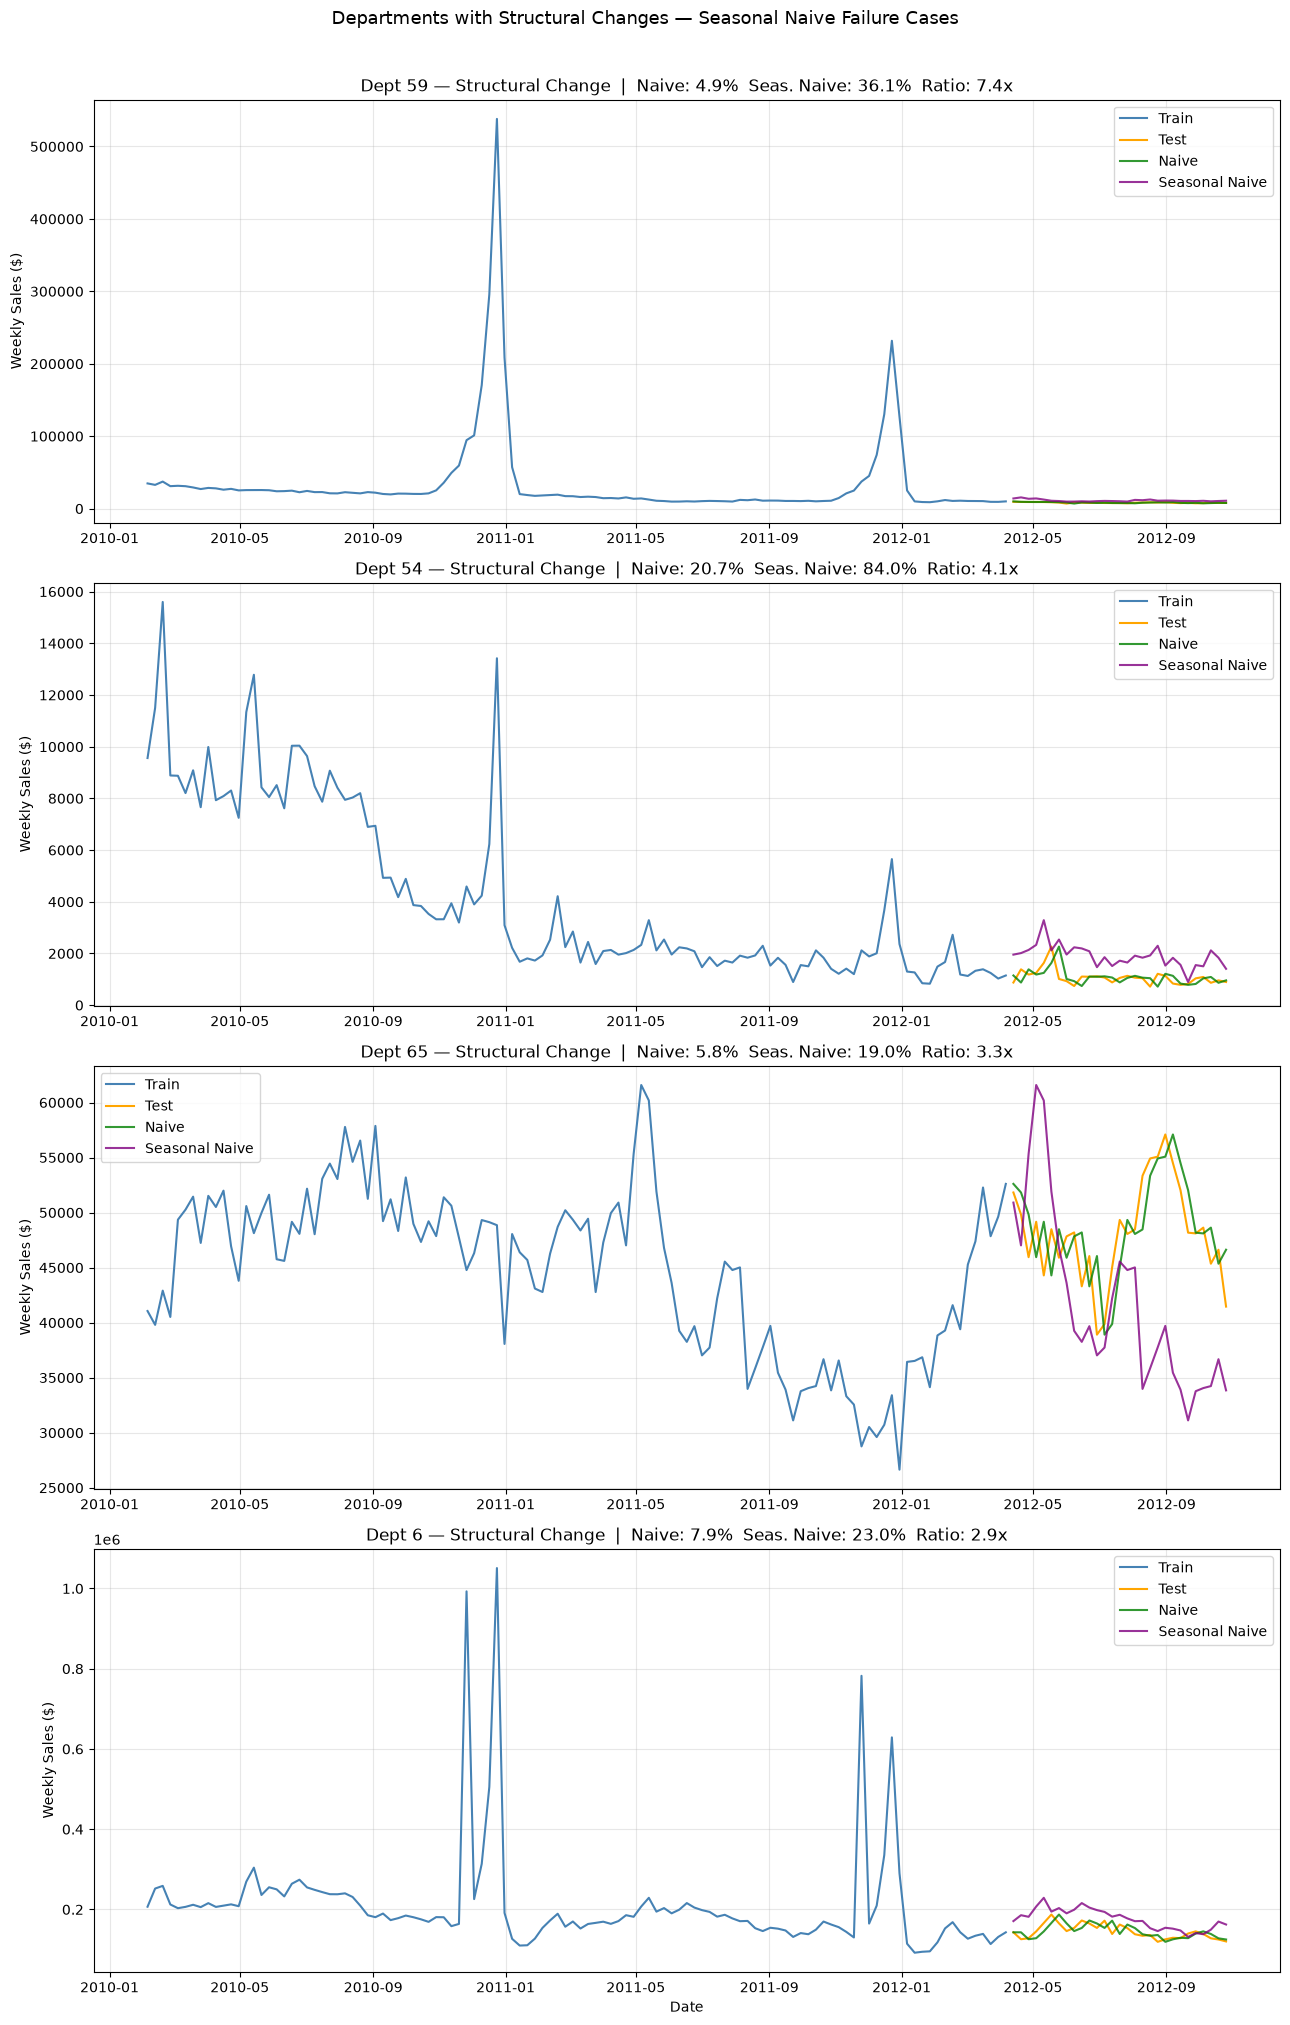

In [24]:
# Visualise the structural change departments (Tier 2 only)
structural_change_depts = [59, 54, 65, 6]

fig, axes = plt.subplots(len(structural_change_depts), 1,
                         figsize=(13, 5 * len(structural_change_depts)))

for ax, dept in zip(axes, structural_change_depts):
    group = dept_sales[dept_sales['Dept'] == dept].sort_values('Date')
    train = group[group['Date'] <= split_date]
    test  = group[group['Date'] >  split_date]
    full  = pd.concat([train['Weekly_Sales'], test['Weekly_Sales']])

    naive_fc  = full.shift(1).iloc[len(train):].values
    seas_fc   = full.shift(52).iloc[len(train):].values

    ax.plot(train['Date'], train['Weekly_Sales'],
            label='Train', color='steelblue')
    ax.plot(test['Date'],  test['Weekly_Sales'],
            label='Test',  color='orange')
    ax.plot(test['Date'],  naive_fc,
            label='Naive', color='green', alpha=0.8)
    ax.plot(test['Date'],  seas_fc,
            label='Seasonal Naive', color='purple', alpha=0.8)

    row = dept_results_df[dept_results_df['Dept'] == dept].iloc[0]
    ax.set_title(
        f"Dept {dept} — Structural Change  |  "
        f"Naive: {row['Naive_MAPE']:.1f}%  "
        f"Seas. Naive: {row['Seasonal_Naive_MAPE']:.1f}%  "
        f"Ratio: {row['Seas_vs_Naive_ratio']:.1f}x"
    )
    ax.set_ylabel("Weekly Sales ($)")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")
fig.suptitle("Departments with Structural Changes — Seasonal Naive Failure Cases",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

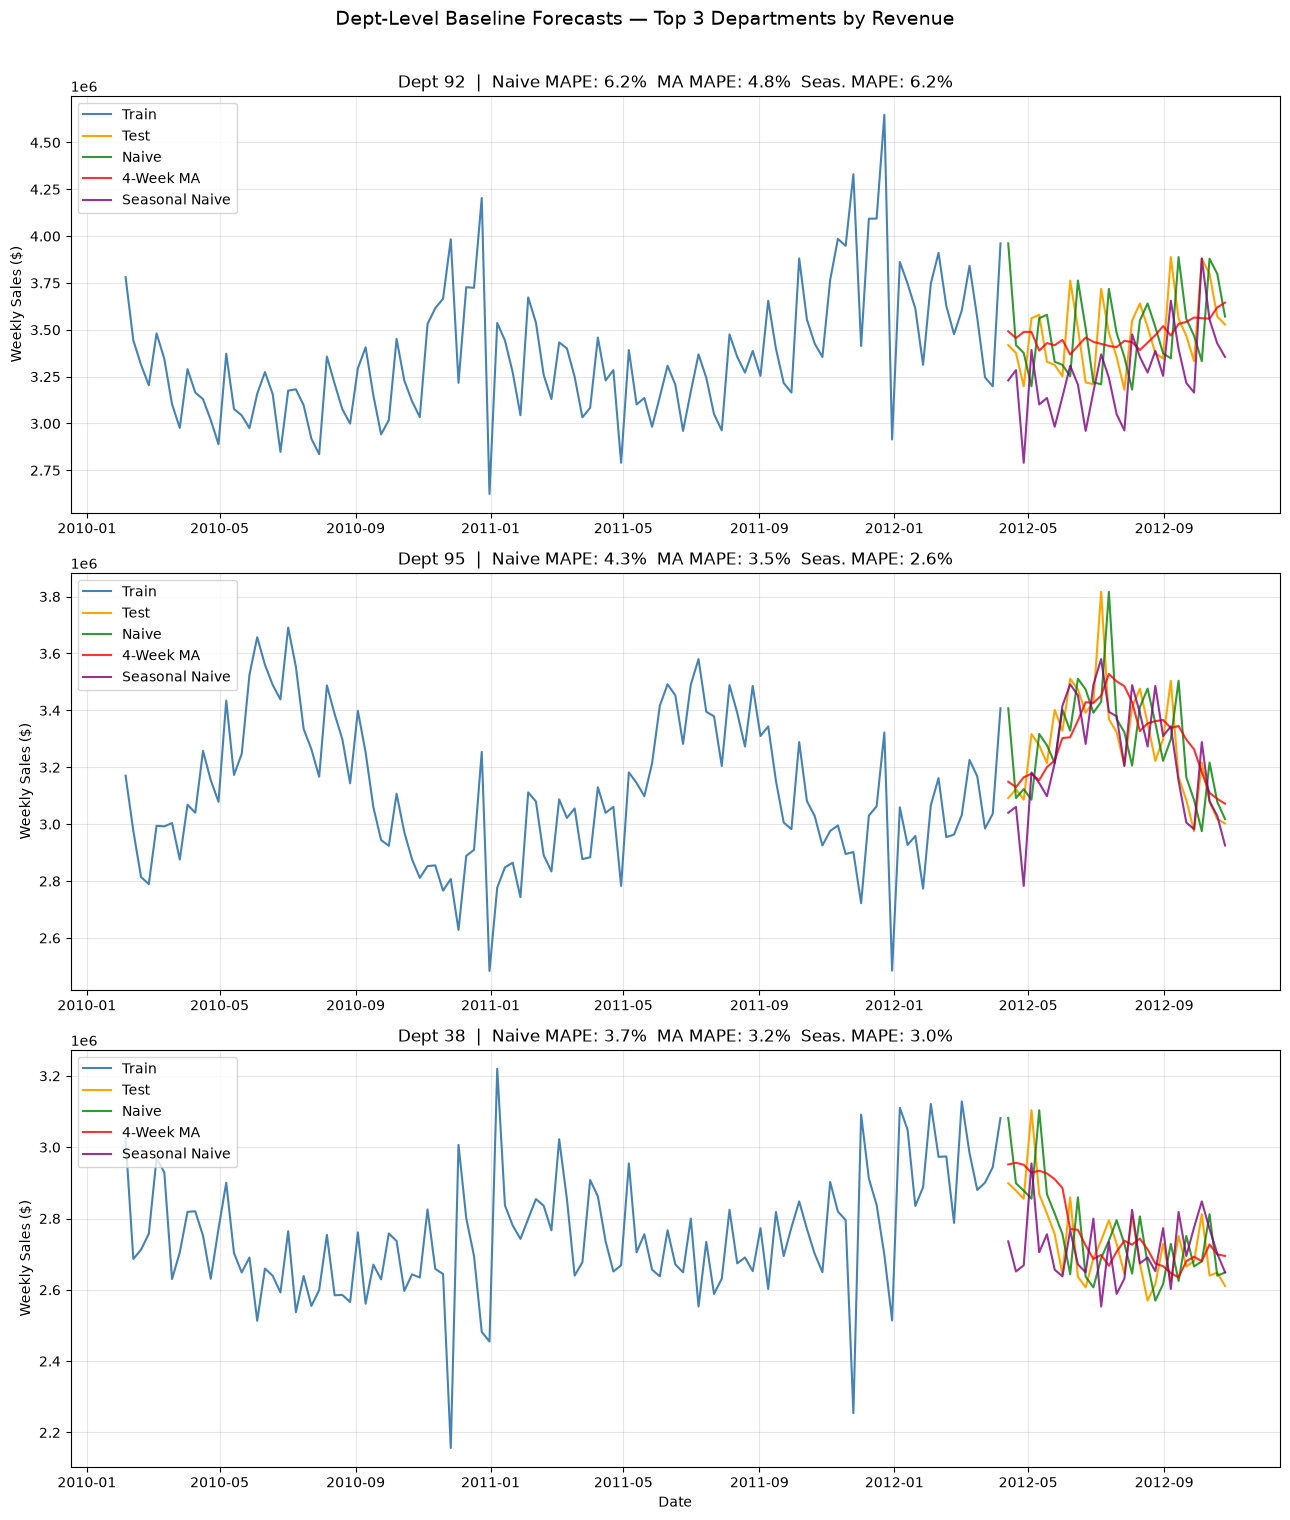

In [25]:
# Plot top 3 departments by total sales
top_depts = (dept_sales
             .groupby('Dept')['Weekly_Sales']
             .sum()
             .nlargest(3)
             .index)

fig, axes = plt.subplots(len(top_depts), 1,
                         figsize=(13, 5 * len(top_depts)),
                         sharex=False)

for ax, dept in zip(axes, top_depts):
    group = dept_sales[dept_sales['Dept'] == dept].sort_values('Date')
    train = group[group['Date'] <= split_date]
    test  = group[group['Date'] >  split_date]
    full  = pd.concat([train['Weekly_Sales'], test['Weekly_Sales']])

    forecasts_plot = {
        'Naive':          full.shift(1).iloc[len(train):].values,
        '4-Week MA':      full.rolling(N_MA).mean().shift(1).iloc[len(train):].values,
        'Seasonal Naive': full.shift(SEAS_LAG).iloc[len(train):].values,
    }

    ax.plot(train['Date'], train['Weekly_Sales'],
            label='Train', color='steelblue')
    ax.plot(test['Date'],  test['Weekly_Sales'],
            label='Test',  color='orange')

    colors = ['green', 'red', 'purple']
    for (label, fc), color in zip(forecasts_plot.items(), colors):
        ax.plot(test['Date'], fc,
                label=label, color=color, alpha=0.8)

    row = dept_results_df[dept_results_df['Dept'] == dept].iloc[0]
    ax.set_title(
        f"Dept {dept}  |  "
        f"Naive MAPE: {row['Naive_MAPE']:.1f}%  "
        f"MA MAPE: {row['MA_4W_MAPE']:.1f}%  "
        f"Seas. MAPE: {row['Seasonal_Naive_MAPE']:.1f}%"
    )
    ax.set_ylabel("Weekly Sales ($)")
    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")
fig.suptitle("Dept-Level Baseline Forecasts — Top 3 Departments by Revenue",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

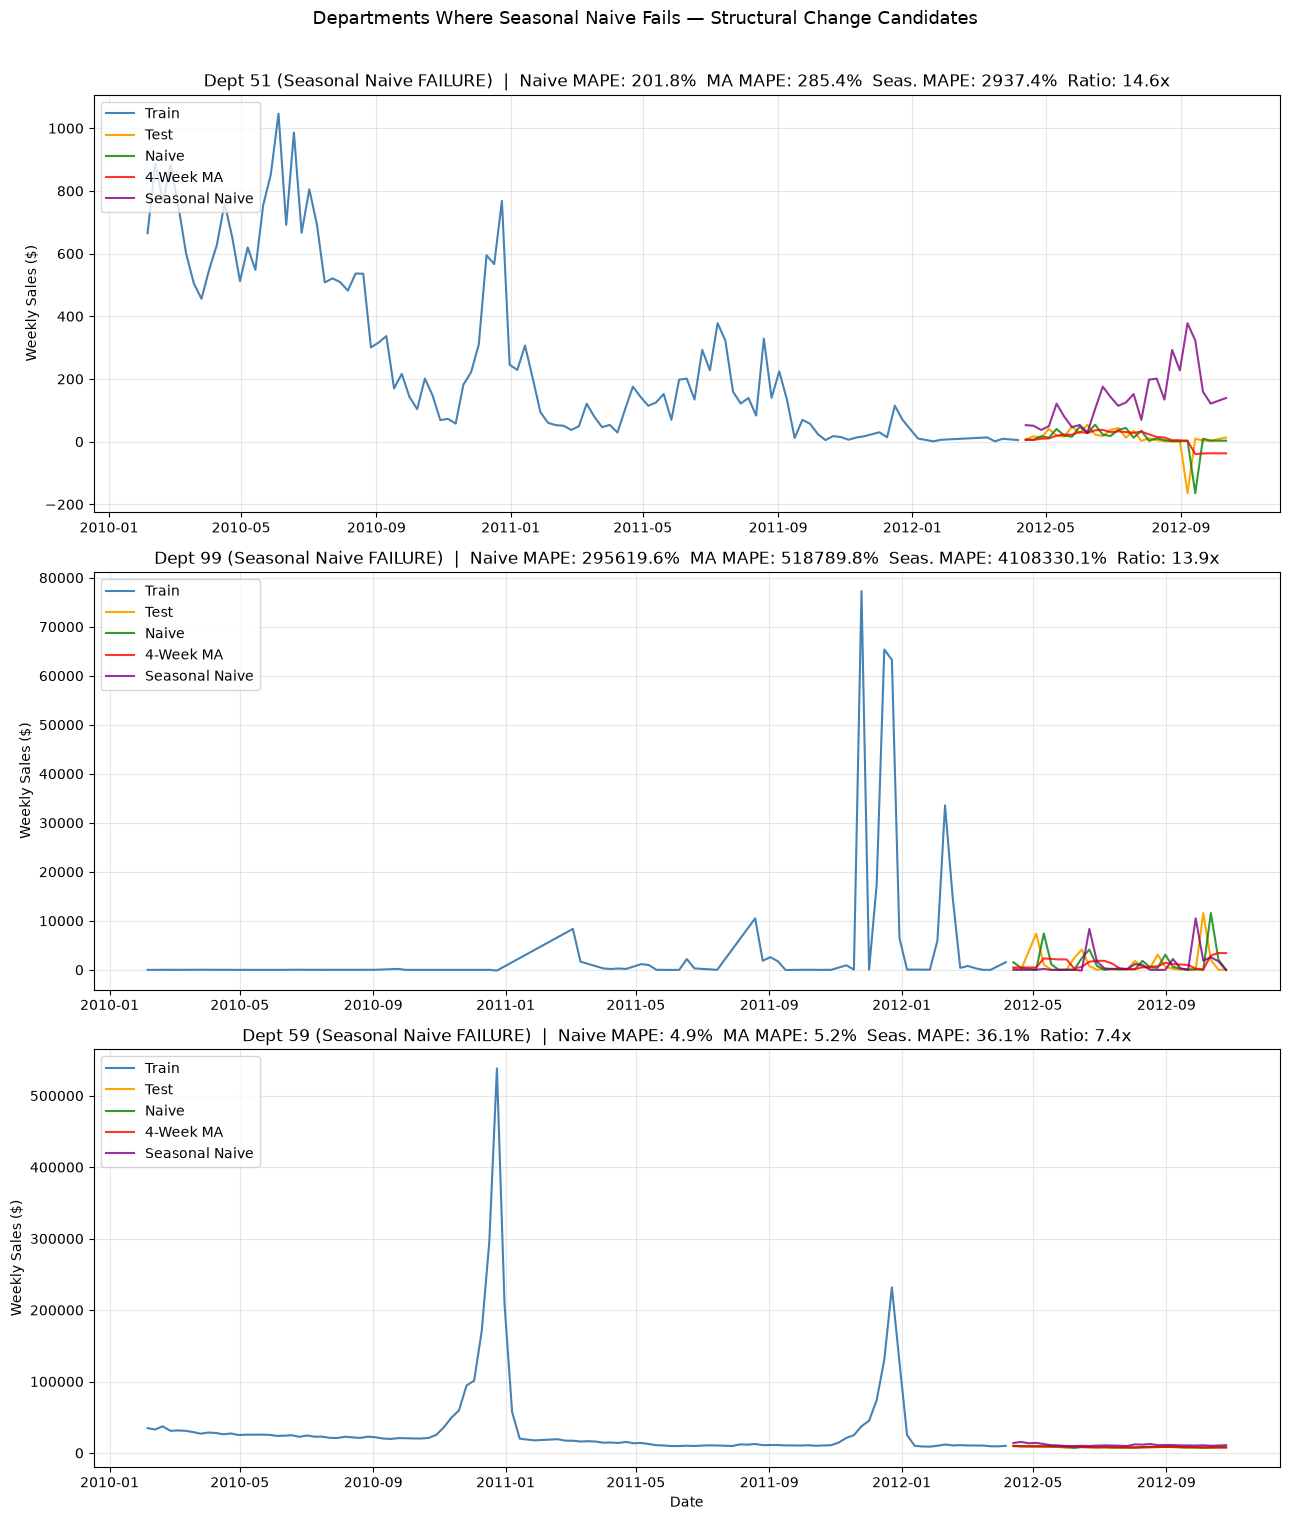

In [26]:
# Step 8: Plot worst Seasonal Naive departments (failure cases)
# ----------------------------------------------------------
if len(seasonal_failures) > 0:
    worst_depts = seasonal_failures.head(3)['Dept'].values

    fig2, axes2 = plt.subplots(len(worst_depts), 1,
                               figsize=(13, 5 * len(worst_depts)),
                               sharex=False)

    # ensure axes2 is always iterable
    if len(worst_depts) == 1:
        axes2 = [axes2]

    for ax, dept in zip(axes2, worst_depts):
        group = dept_sales[dept_sales['Dept'] == dept].sort_values('Date')
        train = group[group['Date'] <= split_date]
        test  = group[group['Date'] >  split_date]
        full  = pd.concat([train['Weekly_Sales'], test['Weekly_Sales']])

        forecasts_plot = {
            'Naive':          full.shift(1).iloc[len(train):].values,
            '4-Week MA':      full.rolling(N_MA).mean().shift(1).iloc[len(train):].values,
            'Seasonal Naive': full.shift(SEAS_LAG).iloc[len(train):].values,
        }

        ax.plot(train['Date'], train['Weekly_Sales'],
                label='Train', color='steelblue')
        ax.plot(test['Date'],  test['Weekly_Sales'],
                label='Test',  color='orange')

        colors = ['green', 'red', 'purple']
        for (label, fc), color in zip(forecasts_plot.items(), colors):
            ax.plot(test['Date'], fc,
                    label=label, color=color, alpha=0.8)

        row = dept_results_df[dept_results_df['Dept'] == dept].iloc[0]
        ax.set_title(
            f"Dept {dept} (Seasonal Naive FAILURE)  |  "
            f"Naive MAPE: {row['Naive_MAPE']:.1f}%  "
            f"MA MAPE: {row['MA_4W_MAPE']:.1f}%  "
            f"Seas. MAPE: {row['Seasonal_Naive_MAPE']:.1f}%  "
            f"Ratio: {row['Seas_vs_Naive_ratio']:.1f}x"
        )
        ax.set_ylabel("Weekly Sales ($)")
        ax.legend(loc='upper left')
        ax.grid(alpha=0.3)

    axes2[-1].set_xlabel("Date")
    fig2.suptitle("Departments Where Seasonal Naive Fails — Structural Change Candidates",
                  fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()